In [1]:
import pandas as pd
import numpy as np

print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

print("Apparel Production Analytics Project Started!")

Pandas Version: 3.1.0
NumPy Version: 2.5.4
Apparel Production Analytics Project Started!


In [2]:
from pathlib import Path

# Get the current working directory
current_folder = Path.cwd()

# Identify the main project folder
if current_folder.name == "notebooks":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

# Locate the production CSV file
file_path = project_folder / "data" / "production_data.csv"

# Check whether the file exists
if file_path.exists():

    # Read CSV using Pandas
    df = pd.read_csv(file_path)

    print("Production dataset loaded successfully!")

else:
    print("CSV file not found:", file_path)

Production dataset loaded successfully!


In [3]:
df.head()

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480,7.0,480,40,28,28
2,2026-10-01,Line 03,TSH-105,2200,2050,5.5,480,30,42,32
3,2026-10-02,Line 01,TSH-101,2000,1920,6.0,480,20,25,30
4,2026-10-02,Line 02,POLO-201,1600,1390,7.0,480,55,45,28


In [4]:
df.shape

(12, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              12 non-null     str    
 1   Production_Line   12 non-null     str    
 2   Style             12 non-null     str    
 3   Target_Qty        12 non-null     int64  
 4   Actual_Qty        12 non-null     int64  
 5   SMV               12 non-null     float64
 6   Shift_Minutes     12 non-null     int64  
 7   Downtime_Minutes  12 non-null     int64  
 8   Defects_Qty       12 non-null     int64  
 9   Operators_Count   12 non-null     int64  
dtypes: float64(1), int64(6), str(3)
memory usage: 1.4 KB


In [6]:
df.describe()

,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
count,12.000000,12.000000,12.000000,12.0,12.000000,12.000000,12.000000
mean,1925.000000,1820.000000,6.250000,480.0,35.416667,34.750000,29.833333
std,248.175158,262.436139,0.657129,0.0,17.510819,12.023651,1.749459
min,1600.000000,1390.000000,5.500000,480.0,15.000000,22.000000,28.000000
25%,1650.000000,1602.500000,5.500000,480.0,23.750000,26.500000,28.000000
50%,1950.000000,1885.000000,6.250000,480.0,30.000000,30.500000,29.500000
75%,2200.000000,1997.500000,7.000000,480.0,43.750000,42.750000,32.000000
max,2200.000000,2180.000000,7.000000,480.0,70.000000,60.000000,32.000000


In [7]:
df.columns

Index(['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV',
       'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count'],
      dtype='str')

In [8]:
df.columns.tolist()

['Date',
 'Production_Line',
 'Style',
 'Target_Qty',
 'Actual_Qty',
 'SMV',
 'Shift_Minutes',
 'Downtime_Minutes',
 'Defects_Qty',
 'Operators_Count']

In [9]:
df["Actual_Qty"]

0     1850
1     1480
2     2050
3     1920
4     1390
5     2140
6     1700
7     1580
8     1980
9     1960
10    1610
11    2180
Name: Actual_Qty, dtype: int64

In [10]:
df[["Production_Line", "Target_Qty", "Actual_Qty"]]

,Production_Line,Target_Qty,Actual_Qty
0,Line 01,2000,1850
1,Line 02,1600,1480
2,Line 03,2200,2050
3,Line 01,2000,1920
4,Line 02,1600,1390
5,Line 03,2200,2140
6,Line 01,1900,1700
7,Line 02,1650,1580
8,Line 03,2200,1980
9,Line 01,1900,1960


In [11]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%Y-%m-%d"
)

In [12]:
df.dtypes

Date                datetime64[us]
Production_Line                str
Style                          str
Target_Qty                   int64
Actual_Qty                   int64
SMV                        float64
Shift_Minutes                int64
Downtime_Minutes             int64
Defects_Qty                  int64
Operators_Count              int64
dtype: object

In [13]:
df.isnull().sum()

Date                0
Production_Line     0
Style               0
Target_Qty          0
Actual_Qty          0
SMV                 0
Shift_Minutes       0
Downtime_Minutes    0
Defects_Qty         0
Operators_Count     0
dtype: int64

In [14]:
# Create a backup of the original dataset

df_raw = df.copy()

print("Original dataset copied successfully!")

Original dataset copied successfully!


In [15]:
df_raw = df.copy()

In [16]:
print("Original dataset:", df.shape)
print("Backup dataset:", df_raw.shape)

Original dataset: (12, 10)
Backup dataset: (12, 10)


In [17]:
# Create a separate dataset for cleaning practice

dirty_df = df_raw.copy()

# Introduce a missing production quantity
dirty_df.loc[2, "Actual_Qty"] = np.nan

# Introduce negative downtime
dirty_df.loc[4, "Downtime_Minutes"] = -15

# Introduce an incorrect defect quantity
dirty_df.loc[6, "Defects_Qty"] = 1800

# Introduce unnecessary spaces
dirty_df.loc[8, "Production_Line"] = " Line 03 "

# Introduce an invalid SMV value
dirty_df.loc[9, "SMV"] = 0

# Add a duplicate production record
dirty_df = pd.concat(
    [dirty_df, dirty_df.iloc[[0]]],
    ignore_index=True
)

print("Training dataset with errors created!")

Training dataset with errors created!


In [18]:
dirty_df.shape

(13, 10)

In [19]:
dirty_df.isnull().sum()

Date                0
Production_Line     0
Style               0
Target_Qty          0
Actual_Qty          1
SMV                 0
Shift_Minutes       0
Downtime_Minutes    0
Defects_Qty         0
Operators_Count     0
dtype: int64

In [20]:
dirty_df[dirty_df.isnull().any(axis=1)]

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
2,2026-10-01,Line 03,TSH-105,2200,NaN,5.5,480,30,42,32


In [21]:
dirty_df.duplicated().sum()

np.int64(1)

In [22]:
dirty_df[dirty_df.duplicated()]

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
12,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30


In [23]:
clean_df = dirty_df.drop_duplicates().copy()

In [24]:
print("Before cleaning:", dirty_df.shape)
print("After removing duplicates:", clean_df.shape)

Before cleaning: (13, 10)
After removing duplicates: (12, 10)


In [25]:
clean_df["Production_Line"] = (
    clean_df["Production_Line"].str.strip()
)

In [26]:
clean_df["Production_Line"].unique()

<ArrowStringArray>
['Line 01', 'Line 02', 'Line 03']
Length: 3, dtype: str

In [27]:
text_columns = ["Production_Line", "Style"]

for column in text_columns:
    clean_df[column] = clean_df[column].str.strip()

In [28]:
invalid_downtime = clean_df[
    (clean_df["Downtime_Minutes"] < 0) |
    (clean_df["Downtime_Minutes"] > clean_df["Shift_Minutes"])
]

invalid_downtime

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
4,2026-10-02,Line 02,POLO-201,1600,1390.0,7.0,480,-15,45,28


In [29]:
invalid_smv = clean_df[
    clean_df["SMV"] <= 0
]

invalid_smv

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
9,2026-10-04,Line 01,TSH-103,1900,1960.0,0.0,480,15,27,29


In [30]:
invalid_defects = clean_df[
    (clean_df["Defects_Qty"] < 0) |
    (clean_df["Defects_Qty"] > clean_df["Actual_Qty"])
]

invalid_defects

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
6,2026-10-03,Line 01,TSH-103,1900,1700.0,6.5,480,60,1800,29


In [31]:
complete_df = clean_df.dropna(
    subset=["Actual_Qty"]
).copy()

In [32]:
invalid_mask = (
    (complete_df["Target_Qty"] <= 0) |
    (complete_df["Actual_Qty"] < 0) |
    (complete_df["SMV"] <= 0) |
    (complete_df["Shift_Minutes"] <= 0) |
    (complete_df["Downtime_Minutes"] < 0) |
    (complete_df["Downtime_Minutes"] > complete_df["Shift_Minutes"]) |
    (complete_df["Defects_Qty"] < 0) |
    (complete_df["Defects_Qty"] > complete_df["Actual_Qty"]) |
    (complete_df["Operators_Count"] <= 0)
)

In [33]:
rejected_records = complete_df[invalid_mask].copy()

valid_df = complete_df[~invalid_mask].copy()

In [34]:
complete_df[invalid_mask]

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
4,2026-10-02,Line 02,POLO-201,1600,1390.0,7.0,480,-15,45,28
6,2026-10-03,Line 01,TSH-103,1900,1700.0,6.5,480,60,1800,29
9,2026-10-04,Line 01,TSH-103,1900,1960.0,0.0,480,15,27,29


In [35]:
complete_df[~invalid_mask]

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28
3,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30
5,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32
7,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28
8,2026-10-03,Line 03,TSH-105,2200,1980.0,5.5,480,70,60,32
10,2026-10-04,Line 02,POLO-202,1650,1610.0,7.0,480,35,22,28
11,2026-10-04,Line 03,TSH-105,2200,2180.0,5.5,480,20,30,32


In [36]:
print("Original records:", len(df_raw))
print("Records after removing duplicates:", len(clean_df))
print("Records with missing actual production:", len(clean_df[clean_df["Actual_Qty"].isna()]))
print("Invalid complete records:", len(rejected_records))
print("Valid production records:", len(valid_df))

Original records: 12
Records after removing duplicates: 12
Records with missing actual production: 1
Invalid complete records: 3
Valid production records: 8


In [37]:
# Create output directory if it doesn't exist

output_folder = project_folder / "output"
output_folder.mkdir(exist_ok=True)

# Save valid production records
valid_df.to_csv(
    output_folder / "valid_production_data.csv",
    index=False
)

# Save invalid records for investigation
rejected_records.to_csv(
    output_folder / "rejected_production_data.csv",
    index=False
)

# Save incomplete records for investigation
incomplete_records = clean_df[
    clean_df["Actual_Qty"].isna()
].copy()

incomplete_records.to_csv(
    output_folder / "incomplete_production_data.csv",
    index=False
)

print("Data cleaning reports generated successfully!")

Data cleaning reports generated successfully!


In [38]:
print("Valid production records:", len(valid_df))

display(valid_df.head())

Valid production records: 8


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28
3,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30
5,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32
7,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28


In [39]:
# Extract target and actual quantities

target_qty = valid_df["Target_Qty"].to_numpy()

actual_qty = valid_df["Actual_Qty"].to_numpy()

print("Target quantities:")
print(target_qty)

print("Actual quantities:")
print(actual_qty)

Target quantities:
[2000 1600 2000 2200 1650 2200 1650 2200]
Actual quantities:
[1850. 1480. 1920. 2140. 1580. 1980. 1610. 2180.]


In [40]:
# Calculate production gap

production_gap = target_qty - actual_qty

print("Production gaps:")
print(production_gap)

Production gaps:
[150. 120.  80.  60.  70. 220.  40.  20.]


In [41]:
# Calculate individual production achievement

achievement_pct = (
    actual_qty / target_qty
) * 100

print("Production achievement percentages:")
print(np.round(achievement_pct, 2))

Production achievement percentages:
[92.5  92.5  96.   97.27 95.76 90.   97.58 99.09]


In [42]:
# Calculate total production target

total_target = np.sum(target_qty)

# Calculate total actual production

total_actual = np.sum(actual_qty)

# Calculate total production gap

total_gap = total_target - total_actual

print("Total Target:", total_target)
print("Total Actual:", total_actual)
print("Total Production Gap:", total_gap)

Total Target: 15500
Total Actual: 14740.0
Total Production Gap: 760.0


In [43]:
overall_achievement = (
    total_actual / total_target
) * 100

print(
    "Overall Achievement:",
    round(overall_achievement, 2), "%"
)

Overall Achievement: 95.1 %


In [44]:
# Extract defect quantities

defects_qty = valid_df["Defects_Qty"].to_numpy()

print(defects_qty)

[35 28 25 31 22 60 22 30]


In [45]:
total_defects = np.sum(defects_qty)

print("Total Defective Garments:", total_defects)

Total Defective Garments: 253


In [46]:
overall_defect_pct = (
    total_defects / total_actual
) * 100

print(
    "Overall Defect Percentage:",
    round(overall_defect_pct, 2), "%"
)

Overall Defect Percentage: 1.72 %


In [47]:
good_qty = actual_qty - defects_qty

total_good_qty = np.sum(good_qty)

print("Total Good Garments:", total_good_qty)

Total Good Garments: 14487.0


In [48]:
print("Maximum Production:", np.max(actual_qty))

print("Minimum Production:", np.min(actual_qty))

print("Average Production:", np.mean(actual_qty))

print("Median Production:", np.median(actual_qty))

print("Standard Deviation:", np.std(actual_qty))

Maximum Production: 2180.0
Minimum Production: 1480.0
Average Production: 1842.5
Median Production: 1885.0
Standard Deviation: 245.39508960042374


In [49]:
# Create a separate DataFrame for analysis

analysis_df = valid_df.copy()

# Add production gap
analysis_df["Production_Gap"] = production_gap

# Add achievement percentage
analysis_df["Achievement_Pct"] = np.round(
    achievement_pct, 2
)

# Add defect percentage for each record
analysis_df["Defect_Pct"] = np.round(
    (defects_qty / actual_qty) * 100, 2
)

# Add performance status
analysis_df["Performance_Status"] = np.where(
    achievement_pct >= 100,
    "Target Achieved",
    "Below Target"
)

display(
    analysis_df[
        [
            "Date",
            "Production_Line",
            "Target_Qty",
            "Actual_Qty",
            "Production_Gap",
            "Achievement_Pct",
            "Defects_Qty",
            "Defect_Pct",
            "Performance_Status"
        ]
    ]
)

,Date,Production_Line,Target_Qty,Actual_Qty,Production_Gap,Achievement_Pct,Defects_Qty,Defect_Pct,Performance_Status
0,2026-10-01,Line 01,2000,1850.0,150.0,92.50,35,1.89,Below Target
1,2026-10-01,Line 02,1600,1480.0,120.0,92.50,28,1.89,Below Target
3,2026-10-02,Line 01,2000,1920.0,80.0,96.00,25,1.30,Below Target
5,2026-10-02,Line 03,2200,2140.0,60.0,97.27,31,1.45,Below Target
7,2026-10-03,Line 02,1650,1580.0,70.0,95.76,22,1.39,Below Target
8,2026-10-03,Line 03,2200,1980.0,220.0,90.00,60,3.03,Below Target
10,2026-10-04,Line 02,1650,1610.0,40.0,97.58,22,1.37,Below Target
11,2026-10-04,Line 03,2200,2180.0,20.0,99.09,30,1.38,Below Target


In [50]:
production_summary = {
    "Total_Production_Target": total_target,
    "Total_Actual_Production": total_actual,
    "Total_Production_Gap": total_gap,
    "Overall_Achievement_Pct": round(overall_achievement, 2),
    "Total_Defects": int(total_defects),
    "Overall_Defect_Pct": round(overall_defect_pct, 2),
    "Total_Good_Production": int(total_good_qty)
}

for key, value in production_summary.items():
    print(f"{key}: {value}")

Total_Production_Target: 15500
Total_Actual_Production: 14740.0
Total_Production_Gap: 760.0
Overall_Achievement_Pct: 95.1
Total_Defects: 253
Overall_Defect_Pct: 1.72
Total_Good_Production: 14487


In [51]:
analysis_file = (
    output_folder / "production_analysis_results.csv"
)

analysis_df.to_csv(
    analysis_file,
    index=False
)

print("Production analysis report generated!")

Production analysis report generated!


In [52]:
# Check our cleaned production dataset

print("Number of valid records:", len(valid_df))

display(valid_df.head())

Number of valid records: 8


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28
3,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30
5,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32
7,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28


In [53]:
# Create an independent copy for efficiency analysis

efficiency_df = valid_df.copy()

print("Efficiency analysis dataset created!")

Efficiency analysis dataset created!


In [54]:
# Calculate good production quantities

actual_qty = efficiency_df["Actual_Qty"].to_numpy()

defects_qty = efficiency_df["Defects_Qty"].to_numpy()

good_qty = np.subtract(actual_qty, defects_qty)

# Add the result to our DataFrame

efficiency_df["Good_Qty"] = good_qty

display(efficiency_df[
    ["Production_Line", "Actual_Qty",
     "Defects_Qty", "Good_Qty"]
])

,Production_Line,Actual_Qty,Defects_Qty,Good_Qty
0,Line 01,1850.0,35,1815.0
1,Line 02,1480.0,28,1452.0
3,Line 01,1920.0,25,1895.0
5,Line 03,2140.0,31,2109.0
7,Line 02,1580.0,22,1558.0
8,Line 03,1980.0,60,1920.0
10,Line 02,1610.0,22,1588.0
11,Line 03,2180.0,30,2150.0


In [55]:
np.subtract(actual_qty, defects_qty)

array([1815., 1452., 1895., 2109., 1558., 1920., 1588., 2150.])

In [56]:
# Extract good quantities and SMV

good_qty = efficiency_df["Good_Qty"].to_numpy()

smv = efficiency_df["SMV"].to_numpy()

# Calculate earned minutes

earned_minutes = np.multiply(good_qty, smv)

# Add earned minutes to our DataFrame

efficiency_df["Earned_Minutes"] = earned_minutes

display(
    efficiency_df[
        ["Production_Line", "Good_Qty", "SMV", "Earned_Minutes"]
    ]
)

,Production_Line,Good_Qty,SMV,Earned_Minutes
0,Line 01,1815.0,6.0,10890.0
1,Line 02,1452.0,7.0,10164.0
3,Line 01,1895.0,6.0,11370.0
5,Line 03,2109.0,5.5,11599.5
7,Line 02,1558.0,7.0,10906.0
8,Line 03,1920.0,5.5,10560.0
10,Line 02,1588.0,7.0,11116.0
11,Line 03,2150.0,5.5,11825.0


In [57]:
# Extract operator count and shift duration

operators = efficiency_df["Operators_Count"].to_numpy()

shift_minutes = efficiency_df["Shift_Minutes"].to_numpy()

# Calculate available labour minutes

available_labour_minutes = np.multiply(
    operators,
    shift_minutes
)

# Add to DataFrame

efficiency_df["Available_Labour_Minutes"] = (
    available_labour_minutes
)

display(
    efficiency_df[
        [
            "Production_Line",
            "Operators_Count",
            "Shift_Minutes",
            "Available_Labour_Minutes"
        ]
    ]
)

,Production_Line,Operators_Count,Shift_Minutes,Available_Labour_Minutes
0,Line 01,30,480,14400
1,Line 02,28,480,13440
3,Line 01,30,480,14400
5,Line 03,32,480,15360
7,Line 02,28,480,13440
8,Line 03,32,480,15360
10,Line 02,28,480,13440
11,Line 03,32,480,15360


In [58]:
# Extract earned minutes and available labour minutes

earned = efficiency_df["Earned_Minutes"].to_numpy()

available = efficiency_df[
    "Available_Labour_Minutes"
].to_numpy()

# Calculate efficiency percentage

efficiency_pct = np.divide(
    earned,
    available
) * 100

# Store efficiency in DataFrame

efficiency_df["Efficiency_Pct"] = np.round(
    efficiency_pct,
    2
)

display(
    efficiency_df[
        [
            "Production_Line",
            "Earned_Minutes",
            "Available_Labour_Minutes",
            "Efficiency_Pct"
        ]
    ]
)

,Production_Line,Earned_Minutes,Available_Labour_Minutes,Efficiency_Pct
0,Line 01,10890.0,14400,75.62
1,Line 02,10164.0,13440,75.62
3,Line 01,11370.0,14400,78.96
5,Line 03,11599.5,15360,75.52
7,Line 02,10906.0,13440,81.15
8,Line 03,10560.0,15360,68.75
10,Line 02,11116.0,13440,82.71
11,Line 03,11825.0,15360,76.99


In [59]:
# Extract downtime

downtime = efficiency_df[
    "Downtime_Minutes"
].to_numpy()

# Calculate downtime percentage

downtime_pct = np.divide(
    downtime,
    shift_minutes
) * 100

efficiency_df["Downtime_Pct"] = np.round(
    downtime_pct,
    2
)

display(
    efficiency_df[
        [
            "Production_Line",
            "Shift_Minutes",
            "Downtime_Minutes",
            "Downtime_Pct"
        ]
    ]
)

,Production_Line,Shift_Minutes,Downtime_Minutes,Downtime_Pct
0,Line 01,480,25,5.21
1,Line 02,480,40,8.33
3,Line 01,480,20,4.17
5,Line 03,480,25,5.21
7,Line 02,480,30,6.25
8,Line 03,480,70,14.58
10,Line 02,480,35,7.29
11,Line 03,480,20,4.17


In [60]:
# Calculate labour minutes lost due to downtime

downtime_labour_minutes = np.multiply(
    downtime,
    operators
)

efficiency_df["Downtime_Labour_Minutes"] = (
    downtime_labour_minutes
)

display(
    efficiency_df[
        [
            "Production_Line",
            "Operators_Count",
            "Downtime_Minutes",
            "Downtime_Labour_Minutes"
        ]
    ]
)

,Production_Line,Operators_Count,Downtime_Minutes,Downtime_Labour_Minutes
0,Line 01,30,25,750
1,Line 02,28,40,1120
3,Line 01,30,20,600
5,Line 03,32,25,800
7,Line 02,28,30,840
8,Line 03,32,70,2240
10,Line 02,28,35,980
11,Line 03,32,20,640


In [61]:
total_downtime = np.sum(downtime)

total_shift_minutes = np.sum(shift_minutes)

overall_downtime_pct = (
    total_downtime / total_shift_minutes
) * 100

print("Total Downtime:", total_downtime, "minutes")

print(
    "Overall Downtime Percentage:",
    round(overall_downtime_pct, 2),
    "%"
)

Total Downtime: 265 minutes
Overall Downtime Percentage: 6.9 %


In [62]:
# Calculate total earned minutes

total_earned_minutes = np.sum(earned)

# Calculate total available labour minutes

total_available_minutes = np.sum(available)

# Calculate overall manufacturing efficiency

overall_efficiency = (
    total_earned_minutes / total_available_minutes
) * 100

print("Total Earned Minutes:", total_earned_minutes)

print(
    "Total Available Labour Minutes:",
    total_available_minutes
)

print(
    "Overall Manufacturing Efficiency:",
    round(overall_efficiency, 2),
    "%"
)

Total Earned Minutes: 88430.5
Total Available Labour Minutes: 115200
Overall Manufacturing Efficiency: 76.76 %


In [63]:
np.mean(efficiency_pct)

np.float64(76.91446940104166)

In [64]:
# Calculate net available labour minutes

net_available_minutes = (
    available - downtime_labour_minutes
)

efficiency_df["Net_Available_Labour_Minutes"] = (
    net_available_minutes
)

In [65]:
# Calculate efficiency excluding downtime

running_efficiency = (
    total_earned_minutes /
    np.sum(net_available_minutes)
) * 100

print(
    "Running-Time Efficiency:",
    round(running_efficiency, 2),
    "%"
)

Running-Time Efficiency: 82.47 %


In [66]:
# Calculate running-time efficiency for each record

running_efficiency_pct = (
    earned / net_available_minutes
) * 100

efficiency_df["Running_Efficiency_Pct"] = np.round(
    running_efficiency_pct,
    2
)

# Display the complete efficiency report

efficiency_report = efficiency_df[
    [
        "Date",
        "Production_Line",
        "Style",
        "Actual_Qty",
        "Good_Qty",
        "SMV",
        "Earned_Minutes",
        "Available_Labour_Minutes",
        "Downtime_Minutes",
        "Efficiency_Pct",
        "Running_Efficiency_Pct"
    ]
]

display(efficiency_report)

,Date,Production_Line,Style,Actual_Qty,Good_Qty,SMV,Earned_Minutes,Available_Labour_Minutes,Downtime_Minutes,Efficiency_Pct,Running_Efficiency_Pct
0,2026-10-01,Line 01,TSH-101,1850.0,1815.0,6.0,10890.0,14400,25,75.62,79.78
1,2026-10-01,Line 02,POLO-201,1480.0,1452.0,7.0,10164.0,13440,40,75.62,82.50
3,2026-10-02,Line 01,TSH-101,1920.0,1895.0,6.0,11370.0,14400,20,78.96,82.39
5,2026-10-02,Line 03,TSH-105,2140.0,2109.0,5.5,11599.5,15360,25,75.52,79.67
7,2026-10-03,Line 02,POLO-202,1580.0,1558.0,7.0,10906.0,13440,30,81.15,86.56
8,2026-10-03,Line 03,TSH-105,1980.0,1920.0,5.5,10560.0,15360,70,68.75,80.49
10,2026-10-04,Line 02,POLO-202,1610.0,1588.0,7.0,11116.0,13440,35,82.71,89.21
11,2026-10-04,Line 03,TSH-105,2180.0,2150.0,5.5,11825.0,15360,20,76.99,80.33


In [67]:
efficiency_df["Efficiency_Status"] = np.select(
    [
        efficiency_df["Efficiency_Pct"] >= 85,
        efficiency_df["Efficiency_Pct"] >= 75
    ],
    [
        "Good",
        "Moderate"
    ],
    default="Needs Improvement"
)

display(
    efficiency_df[
        [
            "Production_Line",
            "Efficiency_Pct",
            "Efficiency_Status"
        ]
    ]
)

,Production_Line,Efficiency_Pct,Efficiency_Status
0,Line 01,75.62,Moderate
1,Line 02,75.62,Moderate
3,Line 01,78.96,Moderate
5,Line 03,75.52,Moderate
7,Line 02,81.15,Moderate
8,Line 03,68.75,Needs Improvement
10,Line 02,82.71,Moderate
11,Line 03,76.99,Moderate


In [68]:
from pathlib import Path

# Identify the main project folder

project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

# Create output folder

output_folder = project_folder / "output"
output_folder.mkdir(exist_ok=True)

# Export efficiency details

efficiency_report.to_csv(
    output_folder / "production_efficiency_report.csv",
    index=False
)

# Create overall management summary

efficiency_summary = pd.DataFrame([{
    "Total_Good_Production": int(np.sum(good_qty)),
    "Total_Earned_Minutes": total_earned_minutes,
    "Total_Available_Labour_Minutes": total_available_minutes,
    "Total_Downtime_Minutes": total_downtime,
    "Downtime_Labour_Minutes": int(np.sum(downtime_labour_minutes)),
    "Overall_Efficiency_Pct": round(overall_efficiency, 2),
    "Running_Efficiency_Pct": round(running_efficiency, 2)
}])

# Export management summary

efficiency_summary.to_csv(
    output_folder / "efficiency_management_summary.csv",
    index=False
)

print("Efficiency reports generated successfully!")

Efficiency reports generated successfully!


In [69]:
print("Total production records:", len(efficiency_df))

display(efficiency_df.head())

Total production records: 8


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count,Good_Qty,Earned_Minutes,Available_Labour_Minutes,Efficiency_Pct,Downtime_Pct,Downtime_Labour_Minutes,Net_Available_Labour_Minutes,Running_Efficiency_Pct,Efficiency_Status
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30,1815.0,10890.0,14400,75.62,5.21,750,13650,79.78,Moderate
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28,1452.0,10164.0,13440,75.62,8.33,1120,12320,82.50,Moderate
3,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30,1895.0,11370.0,14400,78.96,4.17,600,13800,82.39,Moderate
5,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32,2109.0,11599.5,15360,75.52,5.21,800,14560,79.67,Moderate
7,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28,1558.0,10906.0,13440,81.15,6.25,840,12600,86.56,Moderate


In [70]:
# Calculate total actual production by line

production_by_line = (
    efficiency_df
    .groupby("Production_Line")["Actual_Qty"]
    .sum()
)

print(production_by_line)

Production_Line
Line 01    3770.0
Line 02    4670.0
Line 03    6300.0
Name: Actual_Qty, dtype: float64


In [71]:
efficiency_df

,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count,Good_Qty,Earned_Minutes,Available_Labour_Minutes,Efficiency_Pct,Downtime_Pct,Downtime_Labour_Minutes,Net_Available_Labour_Minutes,Running_Efficiency_Pct,Efficiency_Status
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30,1815.0,10890.0,14400,75.62,5.21,750,13650,79.78,Moderate
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28,1452.0,10164.0,13440,75.62,8.33,1120,12320,82.50,Moderate
3,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30,1895.0,11370.0,14400,78.96,4.17,600,13800,82.39,Moderate
5,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32,2109.0,11599.5,15360,75.52,5.21,800,14560,79.67,Moderate
7,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28,1558.0,10906.0,13440,81.15,6.25,840,12600,86.56,Moderate
8,2026-10-03,Line 03,TSH-105,2200,1980.0,5.5,480,70,60,32,1920.0,10560.0,15360,68.75,14.58,2240,13120,80.49,Needs Improvement
10,2026-10-04,Line 02,POLO-202,1650,1610.0,7.0,480,35,22,28,1588.0,11116.0,13440,82.71,7.29,980,12460,89.21,Moderate
11,2026-10-04,Line 03,TSH-105,2200,2180.0,5.5,480,20,30,32,2150.0,11825.0,15360,76.99,4.17,640,14720,80.33,Moderate


In [72]:
target_by_line = (
    efficiency_df
    .groupby("Production_Line")["Target_Qty"]
    .sum()
)

print(target_by_line)

Production_Line
Line 01    4000
Line 02    4900
Line 03    6600
Name: Target_Qty, dtype: int64


In [73]:
records_by_line = (
    efficiency_df
    .groupby("Production_Line")
    .size()
)

print(records_by_line)

Production_Line
Line 01    2
Line 02    3
Line 03    3
dtype: int64


In [74]:
average_production = (
    efficiency_df
    .groupby("Production_Line")["Actual_Qty"]
    .mean()
)

print(average_production.round(2))

Production_Line
Line 01    1885.00
Line 02    1556.67
Line 03    2100.00
Name: Actual_Qty, dtype: float64


In [75]:
maximum_production = (
    efficiency_df
    .groupby("Production_Line")["Actual_Qty"]
    .max()
)

print(maximum_production)

Production_Line
Line 01    1920.0
Line 02    1610.0
Line 03    2180.0
Name: Actual_Qty, dtype: float64


In [76]:
minimum_production = (
    efficiency_df
    .groupby("Production_Line")["Actual_Qty"]
    .min()
)

print(minimum_production)

Production_Line
Line 01    1850.0
Line 02    1480.0
Line 03    1980.0
Name: Actual_Qty, dtype: float64


In [77]:
# Group production records by production line

line_summary = (
    efficiency_df
    .groupby("Production_Line", as_index=False)
    .agg(
        Production_Records=("Date", "count"),
        Production_Days=("Date", "nunique"),

        Total_Target=("Target_Qty", "sum"),
        Total_Actual=("Actual_Qty", "sum"),

        Total_Defects=("Defects_Qty", "sum"),
        Total_Good_Qty=("Good_Qty", "sum"),

        Total_Earned_Minutes=("Earned_Minutes", "sum"),

        Total_Available_Labour_Minutes=(
            "Available_Labour_Minutes", "sum"
        ),

        Total_Downtime_Minutes=("Downtime_Minutes", "sum"),

        Total_Shift_Minutes=("Shift_Minutes", "sum"),

        Total_Downtime_Labour_Minutes=(
            "Downtime_Labour_Minutes", "sum"
        )
    )
)

display(line_summary)

,Production_Line,Production_Records,Production_Days,Total_Target,Total_Actual,Total_Defects,Total_Good_Qty,Total_Earned_Minutes,Total_Available_Labour_Minutes,Total_Downtime_Minutes,Total_Shift_Minutes,Total_Downtime_Labour_Minutes
0,Line 01,2,2,4000,3770.0,60,3710.0,22260.0,28800,45,960,1350
1,Line 02,3,3,4900,4670.0,72,4598.0,32186.0,40320,105,1440,2940
2,Line 03,3,3,6600,6300.0,121,6179.0,33984.5,46080,115,1440,3680


In [78]:
line_summary["Production_Gap"] = (
    line_summary["Total_Target"] -
    line_summary["Total_Actual"]
)

In [79]:
line_summary["Achievement_Pct"] = (
    line_summary["Total_Actual"] /
    line_summary["Total_Target"]
) * 100

In [80]:
line_summary["Defect_Pct"] = (
    line_summary["Total_Defects"] /
    line_summary["Total_Actual"]
) * 100

In [81]:
line_summary["Efficiency_Pct"] = (
    line_summary["Total_Earned_Minutes"] /
    line_summary["Total_Available_Labour_Minutes"]
) * 100

In [82]:
line_summary["Downtime_Pct"] = (
    line_summary["Total_Downtime_Minutes"] /
    line_summary["Total_Shift_Minutes"]
) * 100

In [83]:
net_available = (
    line_summary["Total_Available_Labour_Minutes"] -
    line_summary["Total_Downtime_Labour_Minutes"]
)

line_summary["Running_Efficiency_Pct"] = (
    line_summary["Total_Earned_Minutes"] /
    net_available
) * 100

In [84]:
percentage_columns = [
    "Achievement_Pct",
    "Defect_Pct",
    "Efficiency_Pct",
    "Downtime_Pct",
    "Running_Efficiency_Pct"
]

line_summary[percentage_columns] = (
    line_summary[percentage_columns].round(2)
)

In [85]:
performance_report = line_summary[
    [
        "Production_Line",
        "Production_Records",
        "Total_Target",
        "Total_Actual",
        "Production_Gap",
        "Achievement_Pct",
        "Total_Good_Qty",
        "Defect_Pct",
        "Efficiency_Pct",
        "Total_Downtime_Minutes",
        "Downtime_Pct"
    ]
]

display(performance_report)

,Production_Line,Production_Records,Total_Target,Total_Actual,Production_Gap,Achievement_Pct,Total_Good_Qty,Defect_Pct,Efficiency_Pct,Total_Downtime_Minutes,Downtime_Pct
0,Line 01,2,4000,3770.0,230.0,94.25,3710.0,1.59,77.29,45,4.69
1,Line 02,3,4900,4670.0,230.0,95.31,4598.0,1.54,79.83,105,7.29
2,Line 03,3,6600,6300.0,300.0,95.45,6179.0,1.92,73.75,115,7.99


In [86]:
# Sort production lines by efficiency

ranked_lines = line_summary.sort_values(
    by="Efficiency_Pct",
    ascending=False
)

display(
    ranked_lines[
        [
            "Production_Line",
            "Efficiency_Pct",
            "Achievement_Pct",
            "Downtime_Pct"
        ]
    ]
)

,Production_Line,Efficiency_Pct,Achievement_Pct,Downtime_Pct
1,Line 02,79.83,95.31,7.29
0,Line 01,77.29,94.25,4.69
2,Line 03,73.75,95.45,7.99


In [87]:
line_summary["Efficiency_Rank"] = (
    line_summary["Efficiency_Pct"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

display(
    line_summary[
        [
            "Production_Line",
            "Efficiency_Pct",
            "Efficiency_Rank"
        ]
    ].sort_values("Efficiency_Rank")
)

,Production_Line,Efficiency_Pct,Efficiency_Rank
1,Line 02,79.83,1
0,Line 01,77.29,2
2,Line 03,73.75,3


In [88]:
line_summary["Efficiency_Pct"].rank(method="dense", ascending=False)

0    2.0
1    1.0
2    3.0
Name: Efficiency_Pct, dtype: float64

In [89]:
best_line = line_summary.loc[
    line_summary["Efficiency_Pct"].idxmax()
]

print("Best Production Line:", best_line["Production_Line"])

print("Efficiency:", best_line["Efficiency_Pct"], "%")

Best Production Line: Line 02
Efficiency: 79.83 %


In [90]:
worst_line = line_summary.loc[
    line_summary["Efficiency_Pct"].idxmin()
]

print("Worst Production Line:", worst_line["Production_Line"])

print("Efficiency:", worst_line["Efficiency_Pct"], "%")

Worst Production Line: Line 03
Efficiency: 73.75 %


In [91]:
line_summary["Performance_Status"] = np.select(
    [
        line_summary["Efficiency_Pct"] >= 85,
        line_summary["Efficiency_Pct"] >= 75
    ],
    [
        "Good",
        "Moderate"
    ],
    default="Needs Improvement"
)

display(
    line_summary[
        [
            "Production_Line",
            "Efficiency_Pct",
            "Performance_Status"
        ]
    ].sort_values("Efficiency_Pct", ascending=False)
)

,Production_Line,Efficiency_Pct,Performance_Status
1,Line 02,79.83,Moderate
0,Line 01,77.29,Moderate
2,Line 03,73.75,Needs Improvement


In [92]:
daily_summary = (
    efficiency_df
    .groupby("Date", as_index=False)
    .agg(
        Daily_Target=("Target_Qty", "sum"),
        Daily_Actual=("Actual_Qty", "sum"),
        Daily_Defects=("Defects_Qty", "sum"),
        Daily_Earned_Minutes=("Earned_Minutes", "sum"),
        Daily_Available_Minutes=(
            "Available_Labour_Minutes", "sum"
        )
    )
)

daily_summary["Daily_Gap"] = (
    daily_summary["Daily_Target"] -
    daily_summary["Daily_Actual"]
)

daily_summary["Daily_Achievement_Pct"] = (
    daily_summary["Daily_Actual"] /
    daily_summary["Daily_Target"]
) * 100

daily_summary["Daily_Efficiency_Pct"] = (
    daily_summary["Daily_Earned_Minutes"] /
    daily_summary["Daily_Available_Minutes"]
) * 100

display(daily_summary.round(2))

C:\Users\Abeetha\AppData\Local\Temp\ipykernel_8016\98430970.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily_summary.round(2))


,Date,Daily_Target,Daily_Actual,Daily_Defects,Daily_Earned_Minutes,Daily_Available_Minutes,Daily_Gap,Daily_Achievement_Pct,Daily_Efficiency_Pct
0,2026-10-01,3600,3330.0,63,21054.0,27840,270.0,92.50,75.62
1,2026-10-02,4200,4060.0,56,22969.5,29760,140.0,96.67,77.18
2,2026-10-03,3850,3560.0,82,21466.0,28800,290.0,92.47,74.53
3,2026-10-04,3850,3790.0,52,22941.0,28800,60.0,98.44,79.66


In [93]:

# ==========================================
# LESSON 6 - DAILY PRODUCTION SUMMARY
# ==========================================

# Group production records by Date

daily_summary = (
    efficiency_df
    .groupby("Date", as_index=False)
    .agg(
        Daily_Target=("Target_Qty", "sum"),

        Daily_Actual=("Actual_Qty", "sum"),

        Daily_Defects=("Defects_Qty", "sum"),

        Daily_Good_Qty=("Good_Qty", "sum"),

        Daily_Earned_Minutes=("Earned_Minutes", "sum"),

        Daily_Available_Minutes=(
            "Available_Labour_Minutes", "sum"
        ),

        Daily_Downtime=("Downtime_Minutes", "sum")
    )
)


# ==========================================
# 1. CALCULATE PRODUCTION GAP
# ==========================================

daily_summary["Daily_Gap"] = (
    daily_summary["Daily_Target"] -
    daily_summary["Daily_Actual"]
)


# ==========================================
# 2. CALCULATE PRODUCTION ACHIEVEMENT
# ==========================================

daily_summary["Daily_Achievement_Pct"] = (
    daily_summary["Daily_Actual"] /
    daily_summary["Daily_Target"]
) * 100


# ==========================================
# 3. CALCULATE DEFECT PERCENTAGE
# ==========================================

daily_summary["Daily_Defect_Pct"] = (
    daily_summary["Daily_Defects"] /
    daily_summary["Daily_Actual"]
) * 100


# ==========================================
# 4. CALCULATE DAILY LABOUR EFFICIENCY
# ==========================================

daily_summary["Daily_Efficiency_Pct"] = (
    daily_summary["Daily_Earned_Minutes"] /
    daily_summary["Daily_Available_Minutes"]
) * 100


# ==========================================
# 5. CALCULATE DAILY DOWNTIME PERCENTAGE
# ==========================================

# Total shift minutes are assumed to be
# 480 minutes per production record.

daily_summary["Daily_Downtime_Pct"] = (
    daily_summary["Daily_Downtime"] /
    (daily_summary["Daily_Available_Minutes"] /
     efficiency_df["Shift_Minutes"].iloc[0])
) * 100


# ==========================================
# 6. ROUND NUMERIC COLUMNS ONLY
# ==========================================

numeric_columns = daily_summary.select_dtypes(
    include="number"
).columns

daily_summary[numeric_columns] = (
    daily_summary[numeric_columns].round(2)
)


# ==========================================
# 7. DISPLAY DAILY PRODUCTION REPORT
# ==========================================

print("DAILY PRODUCTION SUMMARY")

display(daily_summary)


# ==========================================
# 8. EXPORT DAILY PRODUCTION REPORT
# ==========================================

daily_summary.to_csv(
    output_folder / "daily_production_summary.csv",
    index=False
)

print("Daily production summary generated successfully!")


DAILY PRODUCTION SUMMARY


,Date,Daily_Target,Daily_Actual,Daily_Defects,Daily_Good_Qty,Daily_Earned_Minutes,Daily_Available_Minutes,Daily_Downtime,Daily_Gap,Daily_Achievement_Pct,Daily_Defect_Pct,Daily_Efficiency_Pct,Daily_Downtime_Pct
0,2026-10-01,3600,3330.0,63,3267.0,21054.0,27840,65,270.0,92.50,1.89,75.62,112.07
1,2026-10-02,4200,4060.0,56,4004.0,22969.5,29760,45,140.0,96.67,1.38,77.18,72.58
2,2026-10-03,3850,3560.0,82,3478.0,21466.0,28800,100,290.0,92.47,2.30,74.53,166.67
3,2026-10-04,3850,3790.0,52,3738.0,22941.0,28800,55,60.0,98.44,1.37,79.66,91.67


Daily production summary generated successfully!


In [94]:

# Install Matplotlib if it is not already installed
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [95]:

# Import Matplotlib
import matplotlib.pyplot as plt

# Check the version
import matplotlib

print("Matplotlib Version:", matplotlib.__version__)
print("Matplotlib is ready!")


Matplotlib Version: 3.11.2
Matplotlib is ready!


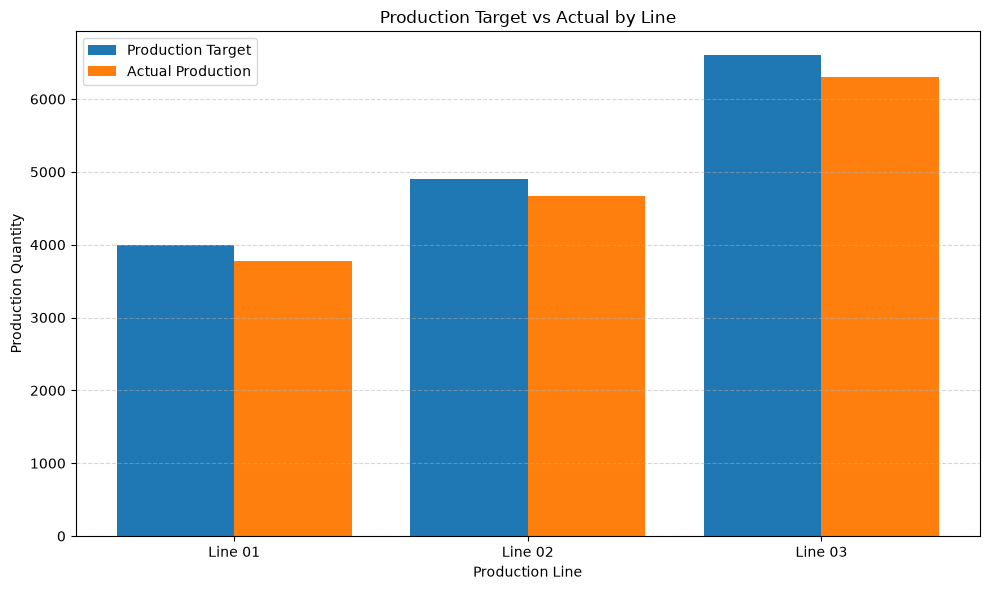

In [96]:

# ==========================================
# CHART 1 - TARGET VS ACTUAL PRODUCTION
# ==========================================

plt.figure(figsize=(10, 6))

# X-axis: Production lines
x = range(len(line_summary))

# Target production bars
plt.bar(
    [i - 0.2 for i in x],
    line_summary["Total_Target"],
    width=0.4,
    label="Production Target"
)

# Actual production bars
plt.bar(
    [i + 0.2 for i in x],
    line_summary["Total_Actual"],
    width=0.4,
    label="Actual Production"
)

# Add chart title and labels
plt.title("Production Target vs Actual by Line")

plt.xlabel("Production Line")

plt.ylabel("Production Quantity")

# Show production line names on X-axis
plt.xticks(
    list(x),
    line_summary["Production_Line"]
)

# Show legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig(
    output_folder / "target_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


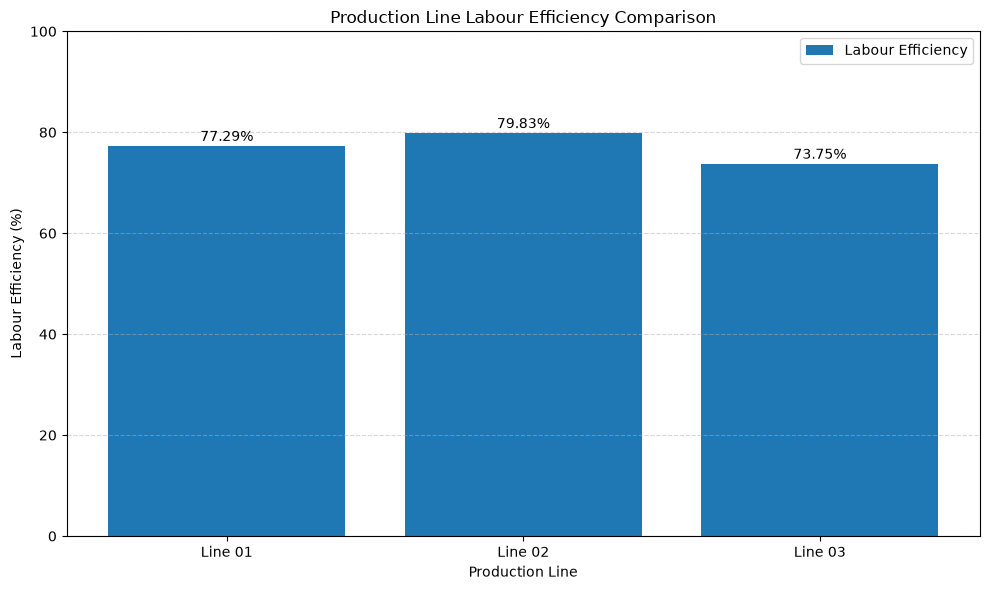

In [97]:

# ==========================================
# CHART 2 - PRODUCTION LINE EFFICIENCY
# ==========================================

plt.figure(figsize=(10, 6))

# Create efficiency bar chart
plt.bar(
    line_summary["Production_Line"],
    line_summary["Efficiency_Pct"],
    label="Labour Efficiency"
)

# Add chart title
plt.title("Production Line Labour Efficiency Comparison")

# Add axis labels
plt.xlabel("Production Line")
plt.ylabel("Labour Efficiency (%)")

# Add percentage labels above each bar
for index, value in enumerate(line_summary["Efficiency_Pct"]):
    plt.text(
        index,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

# Set Y-axis range
plt.ylim(0, 100)

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add legend
plt.legend()

# Adjust chart layout
plt.tight_layout()

# Save chart
plt.savefig(
    output_folder / "production_line_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


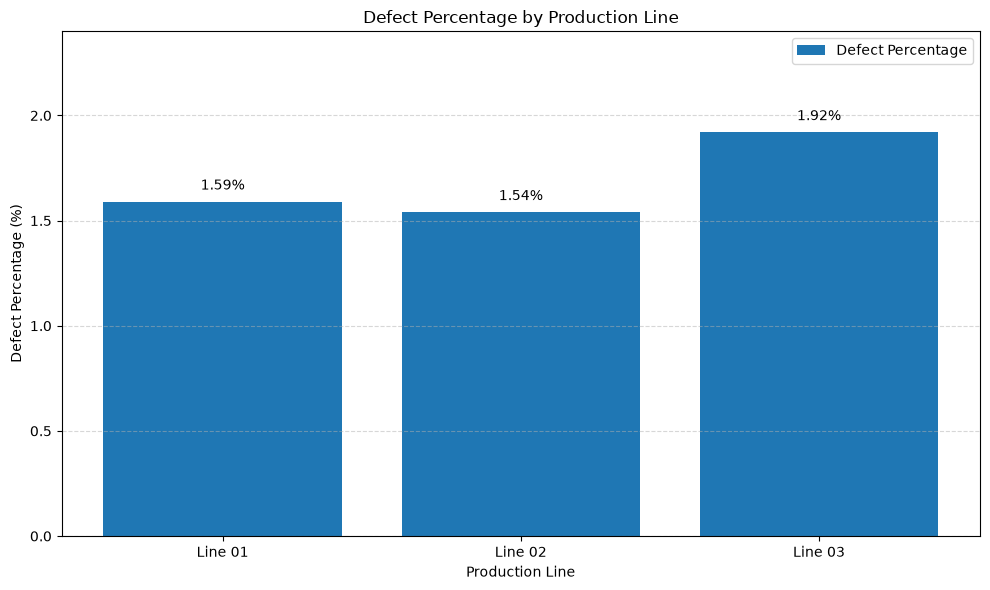

In [98]:

# ==========================================
# CHART 3 - DEFECT PERCENTAGE BY LINE
# ==========================================

plt.figure(figsize=(10, 6))

# Create defect percentage bar chart
plt.bar(
    line_summary["Production_Line"],
    line_summary["Defect_Pct"],
    label="Defect Percentage"
)

# Add chart title
plt.title("Defect Percentage by Production Line")

# Add axis labels
plt.xlabel("Production Line")
plt.ylabel("Defect Percentage (%)")

# Calculate a suitable Y-axis limit
max_defect_pct = line_summary["Defect_Pct"].max()

plt.ylim(
    0,
    max(1, max_defect_pct * 1.25)
)

# Add percentage labels above each bar
for index, value in enumerate(line_summary["Defect_Pct"]):
    plt.text(
        index,
        value + max_defect_pct * 0.03,
        f"{value:.2f}%",
        ha="center"
    )

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add legend
plt.legend()

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig(
    output_folder / "defect_percentage_by_line.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


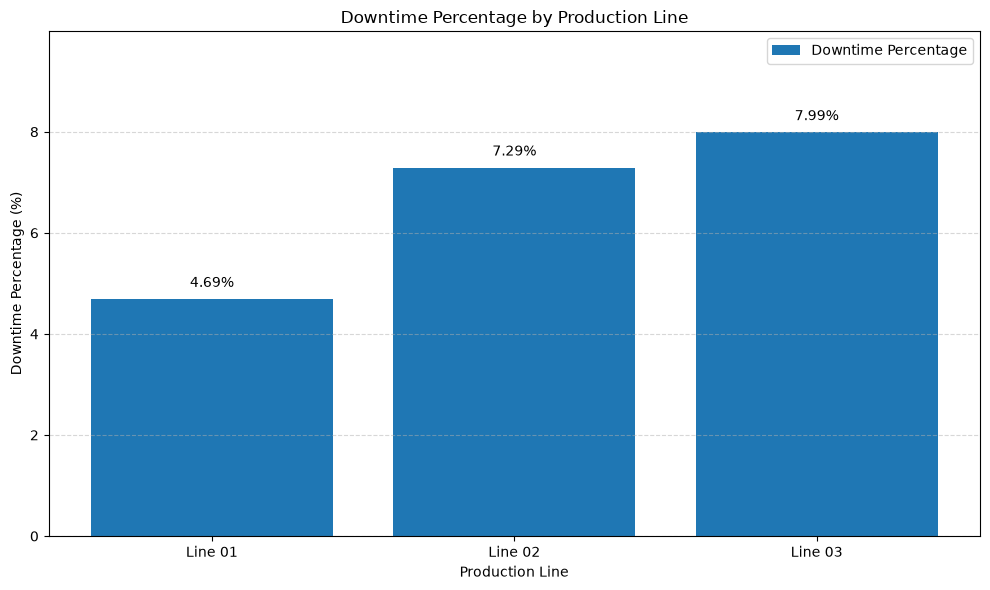

In [99]:

# ==========================================
# CHART 4 - DOWNTIME ANALYSIS BY LINE
# ==========================================

plt.figure(figsize=(10, 6))

# Create downtime percentage bar chart
plt.bar(
    line_summary["Production_Line"],
    line_summary["Downtime_Pct"],
    label="Downtime Percentage"
)

# Add chart title
plt.title("Downtime Percentage by Production Line")

# Add axis labels
plt.xlabel("Production Line")
plt.ylabel("Downtime Percentage (%)")

# Find maximum downtime percentage
max_downtime_pct = line_summary["Downtime_Pct"].max()

# Set Y-axis range dynamically
plt.ylim(
    0,
    max(1, max_downtime_pct * 1.25)
)

# Display percentage labels above each bar
for index, value in enumerate(line_summary["Downtime_Pct"]):
    plt.text(
        index,
        value + max_downtime_pct * 0.03,
        f"{value:.2f}%",
        ha="center"
    )

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add legend
plt.legend()

# Adjust chart layout
plt.tight_layout()

# Save chart
plt.savefig(
    output_folder / "downtime_analysis_by_line.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


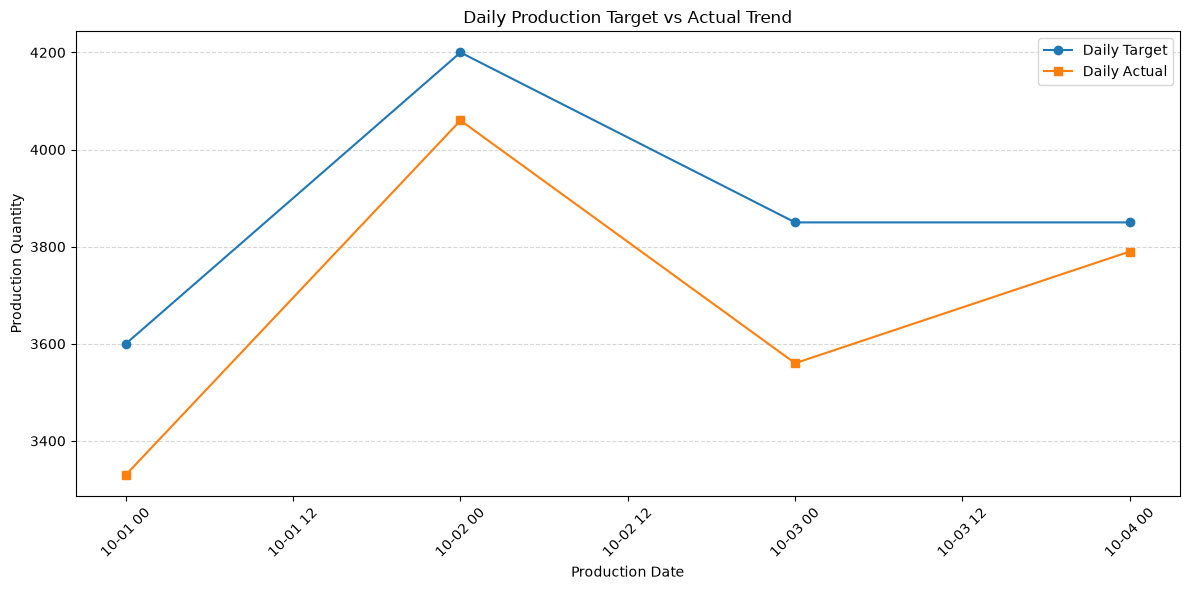

In [100]:

# ==========================================
# CHART 5 - DAILY PRODUCTION TRENDS
# ==========================================

import pandas as pd

# Create a copy of daily summary
daily_plot = daily_summary.copy()

# Convert Date column into datetime format
daily_plot["Date"] = pd.to_datetime(
    daily_plot["Date"],
    errors="coerce"
)

# Remove rows with invalid dates
daily_plot = daily_plot.dropna(subset=["Date"])

# Sort records by date
daily_plot = daily_plot.sort_values("Date")


# ==========================================
# CREATE LINE CHART
# ==========================================

plt.figure(figsize=(12, 6))

# Plot daily production target
plt.plot(
    daily_plot["Date"],
    daily_plot["Daily_Target"],
    marker="o",
    linestyle="-",
    label="Daily Target"
)

# Plot daily actual production
plt.plot(
    daily_plot["Date"],
    daily_plot["Daily_Actual"],
    marker="s",
    linestyle="-",
    label="Daily Actual"
)


# ==========================================
# CHART TITLE AND AXIS LABELS
# ==========================================

plt.title("Daily Production Target vs Actual Trend")

plt.xlabel("Production Date")

plt.ylabel("Production Quantity")


# ==========================================
# CHART FORMATTING
# ==========================================

# Display legend
plt.legend()

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Rotate date labels for better readability
plt.xticks(rotation=45)

# Adjust chart layout
plt.tight_layout()


# ==========================================
# SAVE CHART
# ==========================================

plt.savefig(
    output_folder / "daily_production_trends.png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# DISPLAY CHART
# ==========================================

plt.show()


In [101]:

# ==========================================
# LESSON 8 - STEP 1
# CALCULATE OVERALL MANAGEMENT KPIs
# ==========================================

import pandas as pd
from pathlib import Path

# Ensure output folder exists
output_folder = Path(output_folder)
output_folder.mkdir(parents=True, exist_ok=True)


# ==========================================
# 1. TOTAL PRODUCTION
# ==========================================

total_target = efficiency_df["Target_Qty"].sum()

total_actual = efficiency_df["Actual_Qty"].sum()

total_good_qty = efficiency_df["Good_Qty"].sum()

total_defects = efficiency_df["Defects_Qty"].sum()

production_gap = total_target - total_actual


# ==========================================
# 2. PRODUCTION ACHIEVEMENT
# ==========================================

achievement_pct = (
    (total_actual / total_target) * 100
    if total_target > 0 else 0
)


# ==========================================
# 3. OVERALL LABOUR EFFICIENCY
# ==========================================

total_earned_minutes = (
    efficiency_df["Earned_Minutes"].sum()
)

total_available_labour_minutes = (
    efficiency_df["Available_Labour_Minutes"].sum()
)

efficiency_pct = (
    (total_earned_minutes / total_available_labour_minutes) * 100
    if total_available_labour_minutes > 0 else 0
)


# ==========================================
# 4. OVERALL DEFECT PERCENTAGE
# ==========================================

defect_pct = (
    (total_defects / total_actual) * 100
    if total_actual > 0 else 0
)


# ==========================================
# 5. OVERALL DOWNTIME PERCENTAGE
# ==========================================

total_downtime_minutes = (
    efficiency_df["Downtime_Minutes"].sum()
)

total_shift_minutes = (
    efficiency_df["Shift_Minutes"].sum()
)

downtime_pct = (
    (total_downtime_minutes / total_shift_minutes) * 100
    if total_shift_minutes > 0 else 0
)


# ==========================================
# 6. CREATE KPI SUMMARY
# ==========================================

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Production Target",
        "Total Actual Production",
        "Total Good Production",
        "Total Defects",
        "Production Gap",
        "Production Achievement (%)",
        "Labour Efficiency (%)",
        "Defect Percentage (%)",
        "Downtime Percentage (%)"
    ],

    "Value": [
        total_target,
        total_actual,
        total_good_qty,
        total_defects,
        production_gap,
        achievement_pct,
        efficiency_pct,
        defect_pct,
        downtime_pct
    ]
})

# Round KPI values for display
kpi_summary["Value"] = kpi_summary["Value"].round(2)

# Display KPI summary
display(kpi_summary)

# Export KPI summary
kpi_summary.to_csv(
    output_folder / "management_kpi_summary.csv",
    index=False
)

print("Management KPI summary generated successfully!")


,KPI,Value
0,Total Production Target,15500.00
1,Total Actual Production,14740.00
2,Total Good Production,14487.00
3,Total Defects,253.00
4,Production Gap,760.00
5,Production Achievement (%),95.10
6,Labour Efficiency (%),76.76
7,Defect Percentage (%),1.72
8,Downtime Percentage (%),6.90


Management KPI summary generated successfully!


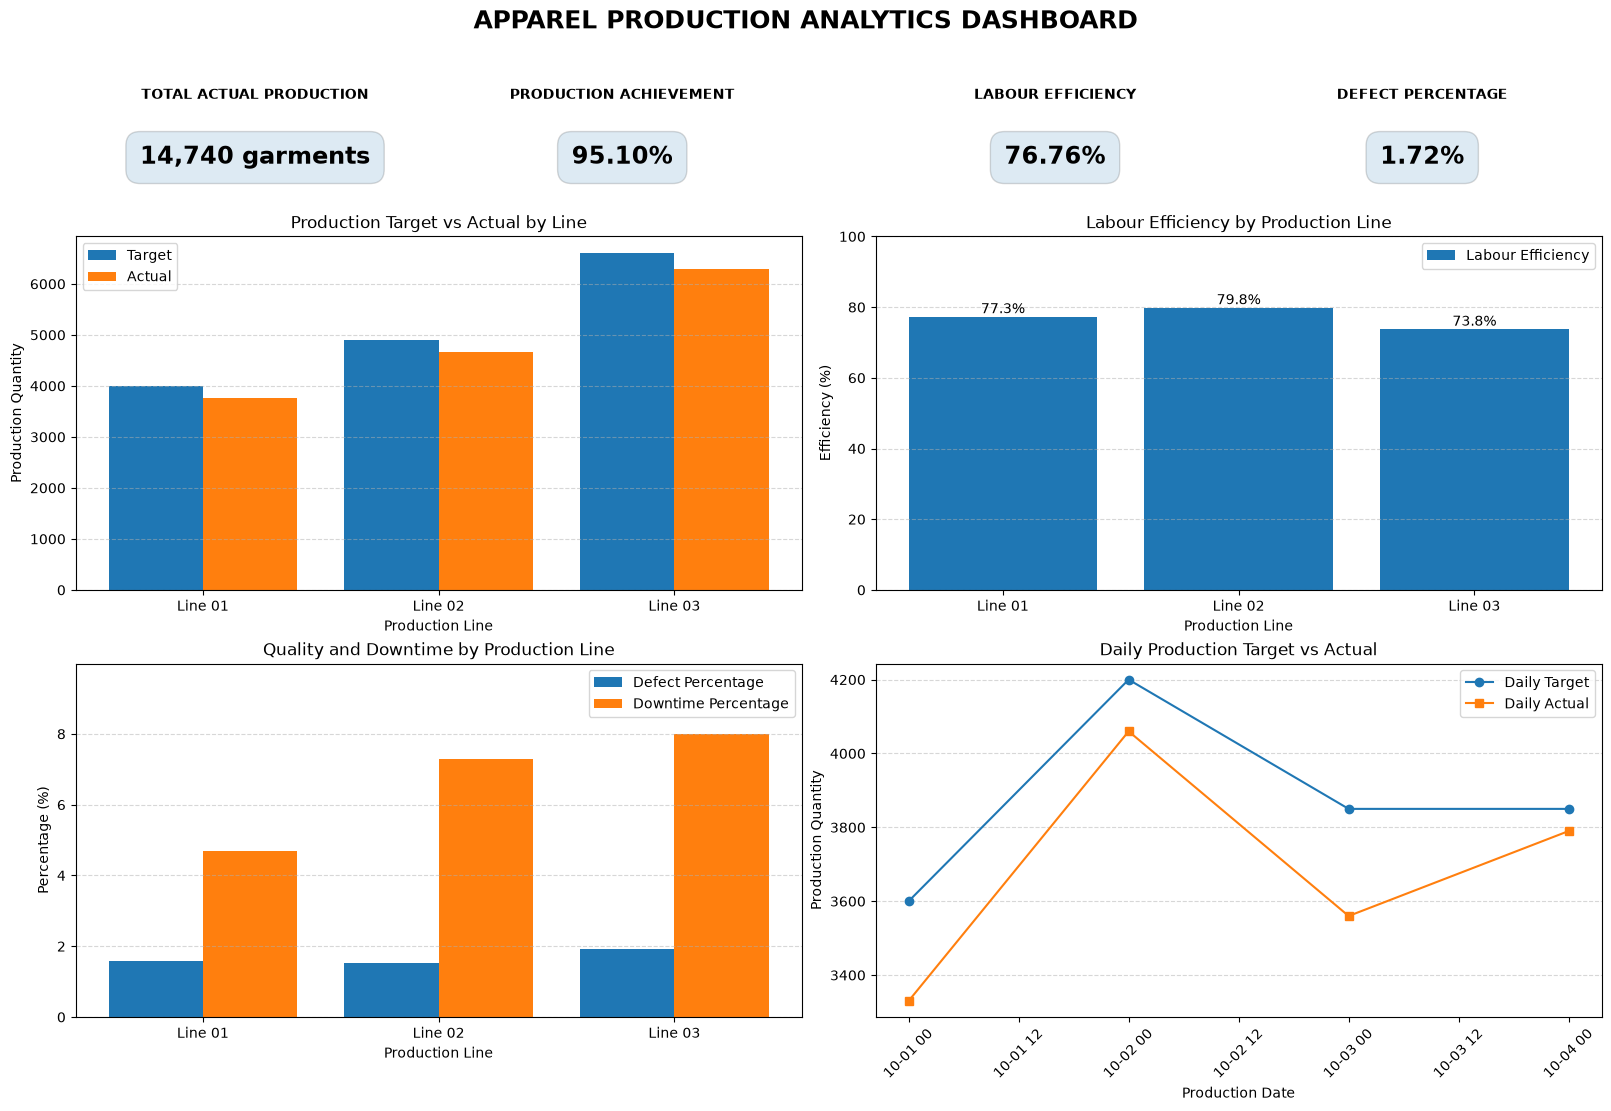

Production Analytics Dashboard generated successfully!
Dashboard saved at: D:\ai_ml_projects\apparel-production-analytics\output\production_analytics_dashboard.png


In [102]:

# ==========================================
# LESSON 8 - STEP 2
# BUILD APPAREL PRODUCTION ANALYTICS DASHBOARD
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd


# ==========================================
# PREPARE DAILY DATA
# ==========================================

daily_plot = daily_summary.copy()

daily_plot["Date"] = pd.to_datetime(
    daily_plot["Date"],
    errors="coerce"
)

daily_plot = (
    daily_plot
    .dropna(subset=["Date"])
    .sort_values("Date")
)


# ==========================================
# CREATE DASHBOARD FIGURE
# ==========================================

fig = plt.figure(
    figsize=(16, 11),
    constrained_layout=True
)

fig.suptitle(
    "APPAREL PRODUCTION ANALYTICS DASHBOARD",
    fontsize=18,
    fontweight="bold"
)

# Divide dashboard into 3 rows and 4 columns
gs = fig.add_gridspec(
    3,
    4,
    height_ratios=[0.65, 1.4, 1.4]
)


# ==========================================
# 1. KPI CARDS
# ==========================================

kpi_cards = [
    ("TOTAL ACTUAL PRODUCTION", f"{total_actual:,.0f} garments"),
    ("PRODUCTION ACHIEVEMENT", f"{achievement_pct:.2f}%"),
    ("LABOUR EFFICIENCY", f"{efficiency_pct:.2f}%"),
    ("DEFECT PERCENTAGE", f"{defect_pct:.2f}%")
]

for index, (label, value) in enumerate(kpi_cards):

    ax = fig.add_subplot(gs[0, index])

    ax.set_axis_off()

    ax.text(
        0.5,
        0.68,
        label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        0.5,
        0.30,
        value,
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.6",
            alpha=0.15
        )
    )


# ==========================================
# 2. TARGET VS ACTUAL PRODUCTION
# ==========================================

ax1 = fig.add_subplot(gs[1, 0:2])

x = range(len(line_summary))

ax1.bar(
    [i - 0.2 for i in x],
    line_summary["Total_Target"],
    width=0.4,
    label="Target"
)

ax1.bar(
    [i + 0.2 for i in x],
    line_summary["Total_Actual"],
    width=0.4,
    label="Actual"
)

ax1.set_title("Production Target vs Actual by Line")

ax1.set_xlabel("Production Line")

ax1.set_ylabel("Production Quantity")

ax1.set_xticks(
    list(x),
    line_summary["Production_Line"]
)

ax1.legend()

ax1.grid(axis="y", linestyle="--", alpha=0.5)


# ==========================================
# 3. LABOUR EFFICIENCY BY LINE
# ==========================================

ax2 = fig.add_subplot(gs[1, 2:4])

ax2.bar(
    line_summary["Production_Line"],
    line_summary["Efficiency_Pct"],
    label="Labour Efficiency"
)

ax2.set_title("Labour Efficiency by Production Line")

ax2.set_xlabel("Production Line")

ax2.set_ylabel("Efficiency (%)")

max_efficiency = line_summary["Efficiency_Pct"].max()

ax2.set_ylim(
    0,
    max(100, max_efficiency * 1.15)
)

for index, value in enumerate(line_summary["Efficiency_Pct"]):

    ax2.text(
        index,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

ax2.legend()

ax2.grid(axis="y", linestyle="--", alpha=0.5)


# ==========================================
# 4. DEFECT AND DOWNTIME COMPARISON
# ==========================================

ax3 = fig.add_subplot(gs[2, 0:2])

line_positions = range(len(line_summary))

ax3.bar(
    [i - 0.2 for i in line_positions],
    line_summary["Defect_Pct"],
    width=0.4,
    label="Defect Percentage"
)

ax3.bar(
    [i + 0.2 for i in line_positions],
    line_summary["Downtime_Pct"],
    width=0.4,
    label="Downtime Percentage"
)

ax3.set_title("Quality and Downtime by Production Line")

ax3.set_xlabel("Production Line")

ax3.set_ylabel("Percentage (%)")

ax3.set_xticks(
    list(line_positions),
    line_summary["Production_Line"]
)

max_rate = max(
    line_summary["Defect_Pct"].max(),
    line_summary["Downtime_Pct"].max()
)

ax3.set_ylim(
    0,
    max(1, max_rate * 1.25)
)

ax3.legend()

ax3.grid(axis="y", linestyle="--", alpha=0.5)


# ==========================================
# 5. DAILY PRODUCTION TRENDS
# ==========================================

ax4 = fig.add_subplot(gs[2, 2:4])

ax4.plot(
    daily_plot["Date"],
    daily_plot["Daily_Target"],
    marker="o",
    label="Daily Target"
)

ax4.plot(
    daily_plot["Date"],
    daily_plot["Daily_Actual"],
    marker="s",
    label="Daily Actual"
)

ax4.set_title("Daily Production Target vs Actual")

ax4.set_xlabel("Production Date")

ax4.set_ylabel("Production Quantity")

ax4.tick_params(
    axis="x",
    labelrotation=45
)

ax4.legend()

ax4.grid(axis="y", linestyle="--", alpha=0.5)


# ==========================================
# 6. SAVE COMPLETE DASHBOARD
# ==========================================

dashboard_path = (
    output_folder / "production_analytics_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# 7. DISPLAY DASHBOARD
# ==========================================

plt.show()

print("Production Analytics Dashboard generated successfully!")

print("Dashboard saved at:", dashboard_path)


In [103]:

# ==========================================
# LESSON 8 - STEP 3
# AUTOMATIC MANAGEMENT INSIGHTS
# ==========================================

# ==========================================
# 1. IDENTIFY BEST AND WORST LINES
# ==========================================

best_efficiency = line_summary.loc[
    line_summary["Efficiency_Pct"].idxmax()
]

worst_efficiency = line_summary.loc[
    line_summary["Efficiency_Pct"].idxmin()
]


# ==========================================
# 2. IDENTIFY QUALITY PERFORMANCE
# ==========================================

highest_defect = line_summary.loc[
    line_summary["Defect_Pct"].idxmax()
]


# ==========================================
# 3. IDENTIFY DOWNTIME PERFORMANCE
# ==========================================

highest_downtime = line_summary.loc[
    line_summary["Downtime_Pct"].idxmax()
]


# ==========================================
# 4. IDENTIFY LARGEST PRODUCTION GAP
# ==========================================

largest_gap = line_summary.loc[
    line_summary["Production_Gap"].idxmax()
]


# ==========================================
# 5. IDENTIFY BEST AND WORST PRODUCTION DAYS
# ==========================================

best_day = daily_summary.loc[
    daily_summary["Daily_Achievement_Pct"].idxmax()
]

worst_day = daily_summary.loc[
    daily_summary["Daily_Achievement_Pct"].idxmin()
]


# ==========================================
# 6. DISPLAY MANAGEMENT INSIGHTS
# ==========================================

print("=" * 55)
print("       APPAREL FACTORY MANAGEMENT INSIGHTS")
print("=" * 55)

print("\n1. BEST LABOUR EFFICIENCY")
print(
    f"{best_efficiency['Production_Line']} achieved "
    f"{best_efficiency['Efficiency_Pct']:.2f}% efficiency."
)

print("\n2. LOWEST LABOUR EFFICIENCY")
print(
    f"{worst_efficiency['Production_Line']} recorded "
    f"{worst_efficiency['Efficiency_Pct']:.2f}% efficiency."
)

print("\n3. HIGHEST DEFECT PERCENTAGE")
print(
    f"{highest_defect['Production_Line']} recorded "
    f"{highest_defect['Defect_Pct']:.2f}% defects."
)

print("\n4. HIGHEST DOWNTIME PERCENTAGE")
print(
    f"{highest_downtime['Production_Line']} recorded "
    f"{highest_downtime['Downtime_Pct']:.2f}% downtime."
)

print("\n5. LARGEST PRODUCTION GAP")
print(
    f"{largest_gap['Production_Line']} has a production gap "
    f"of {largest_gap['Production_Gap']:,.0f} garments."
)

print("\n6. BEST PRODUCTION DAY")
print(
    f"{pd.to_datetime(best_day['Date']).strftime('%Y-%m-%d')} "
    f"achieved {best_day['Daily_Achievement_Pct']:.2f}%."
)

print("\n7. WORST PRODUCTION DAY")
print(
    f"{pd.to_datetime(worst_day['Date']).strftime('%Y-%m-%d')} "
    f"achieved {worst_day['Daily_Achievement_Pct']:.2f}%."
)

print("\n" + "=" * 55)


# ==========================================
# 7. CREATE MANAGEMENT INSIGHTS REPORT
# ==========================================

management_insights = pd.DataFrame([
    {
        "Category": "Best Labour Efficiency",
        "Finding": best_efficiency["Production_Line"],
        "Value": best_efficiency["Efficiency_Pct"]
    },
    {
        "Category": "Lowest Labour Efficiency",
        "Finding": worst_efficiency["Production_Line"],
        "Value": worst_efficiency["Efficiency_Pct"]
    },
    {
        "Category": "Highest Defect Percentage",
        "Finding": highest_defect["Production_Line"],
        "Value": highest_defect["Defect_Pct"]
    },
    {
        "Category": "Highest Downtime Percentage",
        "Finding": highest_downtime["Production_Line"],
        "Value": highest_downtime["Downtime_Pct"]
    },
    {
        "Category": "Largest Production Gap",
        "Finding": largest_gap["Production_Line"],
        "Value": largest_gap["Production_Gap"]
    },
    {
        "Category": "Best Production Day",
        "Finding": pd.to_datetime(
            best_day["Date"]
        ).strftime("%Y-%m-%d"),
        "Value": best_day["Daily_Achievement_Pct"]
    },
    {
        "Category": "Worst Production Day",
        "Finding": pd.to_datetime(
            worst_day["Date"]
        ).strftime("%Y-%m-%d"),
        "Value": worst_day["Daily_Achievement_Pct"]
    }
])

# Export report
management_insights.to_csv(
    output_folder / "management_insights.csv",
    index=False
)

display(management_insights)

print("Management insights report generated successfully!")


       APPAREL FACTORY MANAGEMENT INSIGHTS

1. BEST LABOUR EFFICIENCY
Line 02 achieved 79.83% efficiency.

2. LOWEST LABOUR EFFICIENCY
Line 03 recorded 73.75% efficiency.

3. HIGHEST DEFECT PERCENTAGE
Line 03 recorded 1.92% defects.

4. HIGHEST DOWNTIME PERCENTAGE
Line 03 recorded 7.99% downtime.

5. LARGEST PRODUCTION GAP
Line 03 has a production gap of 300 garments.

6. BEST PRODUCTION DAY
2026-10-04 achieved 98.44%.

7. WORST PRODUCTION DAY
2026-10-03 achieved 92.47%.



,Category,Finding,Value
0,Best Labour Efficiency,Line 02,79.83
1,Lowest Labour Efficiency,Line 03,73.75
2,Highest Defect Percentage,Line 03,1.92
3,Highest Downtime Percentage,Line 03,7.99
4,Largest Production Gap,Line 03,300.00
5,Best Production Day,2026-10-04,98.44
6,Worst Production Day,2026-10-03,92.47


Management insights report generated successfully!


In [104]:
# Validate input DataFrames

if line_summary.empty:
    raise ValueError("Production line summary is empty.")

if daily_summary.empty:
    raise ValueError("Daily production summary is empty.")

print("Production data validation successful!")

Production data validation successful!


In [105]:
# Export the latest production efficiency dataset

efficiency_df.to_csv(
    output_folder / "production_efficiency_report.csv",
    index=False
)

print("Production efficiency dataset exported successfully!")

Production efficiency dataset exported successfully!


In [106]:
from pathlib import Path
import pandas as pd

output_folder = Path(
    r"D:\ai_ml_projects\apparel-production-analytics\output"
)

files_to_check = [
    "valid_production_data.csv",
    "rejected_production_data.csv",
    "incomplete_production_data.csv"
]

for filename in files_to_check:

    file_path = output_folder / filename

    if file_path.exists():

        temp_df = pd.read_csv(file_path)

        print("\nFile:", filename)
        print("Records:", len(temp_df))
        print("Columns:", temp_df.columns.tolist())

    else:
        print(filename, "not found")


File: valid_production_data.csv
Records: 8
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']

File: rejected_production_data.csv
Records: 3
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']

File: incomplete_production_data.csv
Records: 1
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']


In [107]:
# Load previously generated datasets

valid_data = pd.read_csv(
    output_folder / "valid_production_data.csv"
)

rejected_data = pd.read_csv(
    output_folder / "rejected_production_data.csv"
)

# Required production columns

required_columns = [
    "Date",
    "Production_Line",
    "Style",
    "Target_Qty",
    "Actual_Qty",
    "SMV",
    "Shift_Minutes",
    "Downtime_Minutes",
    "Defects_Qty",
    "Operators_Count"
]

# Check both datasets contain the required columns

for name, dataset in [
    ("Valid", valid_data),
    ("Rejected", rejected_data)
]:

    missing = [
        col for col in required_columns
        if col not in dataset.columns
    ]

    if missing:
        raise ValueError(
            f"{name} dataset is missing: {missing}"
        )

# Combine the two datasets

production_data = pd.concat(
    [
        valid_data[required_columns],
        rejected_data[required_columns]
    ],
    ignore_index=True
)

# Export reconstructed dataset

production_data.to_csv(
    output_folder / "production_data_for_validation.csv",
    index=False
)

print("Reconstructed dataset successfully!")
print("Total records:", len(production_data))

Reconstructed dataset successfully!
Total records: 11


In [108]:

# ==========================================
# INVESTIGATE ORIGINAL PRODUCTION RECORDS
# ==========================================

files_to_check = [
    "valid_production_data.csv",
    "rejected_production_data.csv",
    "incomplete_production_data.csv"
]

for filename in files_to_check:

    file_path = output_folder / filename

    print("\n" + "=" * 50)
    print("FILE:", filename)
    print("=" * 50)

    if file_path.exists():

        temp_df = pd.read_csv(file_path)

        print("Number of records:", len(temp_df))

        print("Number of columns:", len(temp_df.columns))

        print("Columns:", temp_df.columns.tolist())

        display(temp_df)

    else:

        print("File not found!")



FILE: valid_production_data.csv
Number of records: 8
Number of columns: 10
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28
2,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30
3,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32
4,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28
5,2026-10-03,Line 03,TSH-105,2200,1980.0,5.5,480,70,60,32
6,2026-10-04,Line 02,POLO-202,1650,1610.0,7.0,480,35,22,28
7,2026-10-04,Line 03,TSH-105,2200,2180.0,5.5,480,20,30,32



FILE: rejected_production_data.csv
Number of records: 3
Number of columns: 10
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-02,Line 02,POLO-201,1600,1390.0,7.0,480,-15,45,28
1,2026-10-03,Line 01,TSH-103,1900,1700.0,6.5,480,60,1800,29
2,2026-10-04,Line 01,TSH-103,1900,1960.0,0.0,480,15,27,29



FILE: incomplete_production_data.csv
Number of records: 1
Number of columns: 10
Columns: ['Date', 'Production_Line', 'Style', 'Target_Qty', 'Actual_Qty', 'SMV', 'Shift_Minutes', 'Downtime_Minutes', 'Defects_Qty', 'Operators_Count']


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 03,TSH-105,2200,NaN,5.5,480,30,42,32


In [109]:

# ==========================================
# CHECK OVERLAPPING RECORDS
# ==========================================

valid_data = pd.read_csv(
    output_folder / "valid_production_data.csv"
)

rejected_data = pd.read_csv(
    output_folder / "rejected_production_data.csv"
)

incomplete_data = pd.read_csv(
    output_folder / "incomplete_production_data.csv"
)

required_columns = [
    "Date",
    "Production_Line",
    "Style",
    "Target_Qty",
    "Actual_Qty",
    "SMV",
    "Shift_Minutes",
    "Downtime_Minutes",
    "Defects_Qty",
    "Operators_Count"
]


# Compare records using the production columns

all_records = pd.concat(
    [
        valid_data[required_columns],
        rejected_data[required_columns],
        incomplete_data[required_columns]
    ],
    ignore_index=True
)

duplicate_mask = all_records.duplicated(
    subset=required_columns,
    keep=False
)

print("Valid records:", len(valid_data))

print("Rejected records:", len(rejected_data))

print("Incomplete records:", len(incomplete_data))

print("Combined records:", len(all_records))

print("Records involved in exact duplicates:", duplicate_mask.sum())

# Display potentially overlapping records

if duplicate_mask.any():

    display(all_records.loc[duplicate_mask])

else:

    print("No exact duplicate records found.")


Valid records: 8
Rejected records: 3
Incomplete records: 1
Combined records: 12
Records involved in exact duplicates: 0
No exact duplicate records found.


In [110]:

# ==========================================
# RECONSTRUCT ORIGINAL PRODUCTION DATASET
# ==========================================

import pandas as pd

# Required production columns

required_columns = [
    "Date",
    "Production_Line",
    "Style",
    "Target_Qty",
    "Actual_Qty",
    "SMV",
    "Shift_Minutes",
    "Downtime_Minutes",
    "Defects_Qty",
    "Operators_Count"
]


# ==========================================
# 1. LOAD ALL THREE DATASETS
# ==========================================

valid_data = pd.read_csv(
    output_folder / "valid_production_data.csv"
)

rejected_data = pd.read_csv(
    output_folder / "rejected_production_data.csv"
)

incomplete_data = pd.read_csv(
    output_folder / "incomplete_production_data.csv"
)


# ==========================================
# 2. VALIDATE DATASET STRUCTURE
# ==========================================

datasets = [
    ("Valid", valid_data),
    ("Rejected", rejected_data),
    ("Incomplete", incomplete_data)
]

for name, dataset in datasets:

    missing_columns = [
        col for col in required_columns
        if col not in dataset.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{name} dataset is missing: {missing_columns}"
        )


# ==========================================
# 3. COMBINE ALL RECORDS
# ==========================================

production_data = pd.concat(
    [
        valid_data[required_columns],
        rejected_data[required_columns],
        incomplete_data[required_columns]
    ],
    ignore_index=True
)


# ==========================================
# 4. CHECK DUPLICATE RECORDS
# ==========================================

duplicate_mask = production_data.duplicated(
    subset=required_columns,
    keep=False
)

print("Total records:", len(production_data))

print(
    "Records involved in exact duplicates:",
    duplicate_mask.sum()
)


# ==========================================
# 5. EXPORT RECONSTRUCTED DATASET
# ==========================================

production_file = (
    output_folder / "production_data_for_validation.csv"
)

production_data.to_csv(
    production_file,
    index=False
)


# ==========================================
# 6. DISPLAY RESULTS
# ==========================================

print("\nOriginal production dataset reconstructed!")

print("Valid source records:", len(valid_data))

print("Rejected source records:", len(rejected_data))

print("Incomplete source records:", len(incomplete_data))

print("Total reconstructed records:", len(production_data))

print("Saved file:", production_file)

display(production_data)


Total records: 12
Records involved in exact duplicates: 0

Original production dataset reconstructed!
Valid source records: 8
Rejected source records: 3
Incomplete source records: 1
Total reconstructed records: 12
Saved file: D:\ai_ml_projects\apparel-production-analytics\output\production_data_for_validation.csv


,Date,Production_Line,Style,Target_Qty,Actual_Qty,SMV,Shift_Minutes,Downtime_Minutes,Defects_Qty,Operators_Count
0,2026-10-01,Line 01,TSH-101,2000,1850.0,6.0,480,25,35,30
1,2026-10-01,Line 02,POLO-201,1600,1480.0,7.0,480,40,28,28
2,2026-10-02,Line 01,TSH-101,2000,1920.0,6.0,480,20,25,30
3,2026-10-02,Line 03,TSH-105,2200,2140.0,5.5,480,25,31,32
4,2026-10-03,Line 02,POLO-202,1650,1580.0,7.0,480,30,22,28
5,2026-10-03,Line 03,TSH-105,2200,1980.0,5.5,480,70,60,32
6,2026-10-04,Line 02,POLO-202,1650,1610.0,7.0,480,35,22,28
7,2026-10-04,Line 03,TSH-105,2200,2180.0,5.5,480,20,30,32
8,2026-10-02,Line 02,POLO-201,1600,1390.0,7.0,480,-15,45,28
9,2026-10-03,Line 01,TSH-103,1900,1700.0,6.5,480,60,1800,29


In [111]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.
